# Clustering with K-Means and DBSCAN

> Explore unsupervised grouping and understand why cluster labels are not ground truth.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Compare centroid-based K-Means with density-based DBSCAN.
- Understand the effects of feature scaling and distance choice.
- Use silhouette score cautiously and inspect clusters visually.

Clustering has no label to optimize in an ordinary unsupervised setting. A cluster number is an arbitrary identifier, not an ordered ranking or a semantic class.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

X, _ = make_moons(n_samples=500, noise=.08, random_state=42)
X = StandardScaler().fit_transform(X)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
dbscan = DBSCAN(eps=.25, min_samples=7).fit_predict(X)
print("KMeans silhouette:", round(silhouette_score(X,kmeans),3))
print("DBSCAN labels (including -1 noise):", np.unique(dbscan, return_counts=True))

KMeans silhouette: 0.493
DBSCAN labels (including -1 noise): (array([-1,  0,  1]), array([  1, 249, 250]))


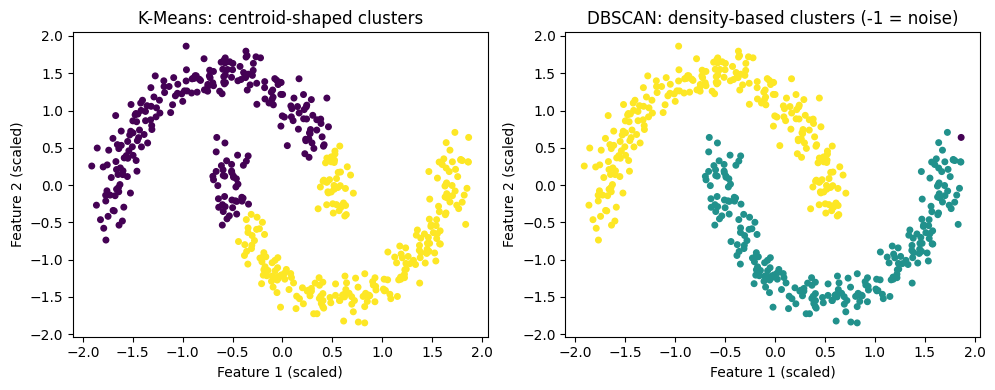

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X[:,0], X[:,1], c=kmeans, s=16, cmap="viridis")
axes[0].set_title("K-Means: centroid-shaped clusters")
axes[1].scatter(X[:,0], X[:,1], c=dbscan, s=16, cmap="viridis")
axes[1].set_title("DBSCAN: density-based clusters (-1 = noise)")
for ax in axes: ax.set_xlabel("Feature 1 (scaled)"); ax.set_ylabel("Feature 2 (scaled)")
plt.tight_layout()

## Choosing a method
- K-Means works best when clusters are roughly compact and distance to a centroid is meaningful.
- DBSCAN can identify irregular clusters and noise, but `eps` and `min_samples` depend on scale and density.
- Standardization may be essential when units differ.
- Silhouette score favors certain geometries and may not reflect business usefulness. Inspect cluster sizes, feature profiles, and stability.

In [3]:
# A cluster profile is usually more useful than the label itself.
cluster_df = pd.DataFrame(X, columns=["feature_1", "feature_2"])
cluster_df["cluster"] = kmeans
print(cluster_df.groupby("cluster").mean().round(2))

         feature_1  feature_2
cluster                      
0            -0.75       0.77
1             0.76      -0.77


## Practice
Try `eps` values 0.15, 0.25, and 0.40 for DBSCAN. Track the number of clusters and noise points. Explain why one setting cannot be assumed best for every dataset.